# GPG-005 — Feature Engineering

**Project:** Gender Wage Gap — Data Mining Final Project
**Input:** `data/processed/cps_model_train.csv.gz` / `cps_model_test.csv.gz` + `model_features.json` produced by
`notebooks/GPG-003_preprocessing.ipynb` (run that notebook first). These are already cleaned, one-hot encoded,
scaled (train-fitted) and split 80/20 stratified by `female`.
**Target:** `ln_realhrwage`. **Weight:** `sample_weight` (`wtsupp`).

**Scope (from `docs/GPG-005.md`)**
1. ≥ 2 new meaningful features — here: an **occupation-level gender segregation index** and an
   **education × occupation skill-tier interaction**.
2. Feature selection (VIF / correlation + Lasso + Random Forest importance).
3. PCA on the high-dimensional occupation/industry dummy block, if it helps.
4. Justify what is retained or removed — all decisions are driven by the numbers produced below and written out
   to `docs/results/GPG-005_findings.md`.


## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import json
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = ROOT / "data" / "processed"
TRAIN_PATH, TEST_PATH, FEAT_PATH = PROC_DIR / "cps_model_train.csv.gz", PROC_DIR / "cps_model_test.csv.gz", PROC_DIR / "model_features.json"
FIG_DIR = ROOT / "docs" / "figures" / "GPG-005"
RES_DIR = ROOT / "docs" / "results"
for d in (FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)
if not TRAIN_PATH.exists():
    raise FileNotFoundError(f"{TRAIN_PATH} not found - run notebooks/GPG-003_preprocessing.ipynb first.")

MEN, WOMEN = "#2a78d6", "#eb6834"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_orange", [WOMEN, "#efeeeb", MEN])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 100, "lines.linewidth": 2,
})

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


## 1. Load the model-ready data

In [2]:
train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)
feat_meta = json.load(open(FEAT_PATH))
TARGET, WEIGHT, BASE_FEATURES = feat_meta["target"], feat_meta["weight"], feat_meta["features"]
print(f"train {train.shape}, test {test.shape}, base features {len(BASE_FEATURES)}")
print(f"female share -- train {train['female'].mean():.3f}, test {test['female'].mean():.3f}")


train (275429, 98), test (68858, 98), base features 96
female share -- train 0.489, test 0.489


## 2. New feature #1 — occupation-level gender segregation index

The cleaned data carries 21 mutually-exclusive binary occupation flags (`manager`, `business`, ... `production`);
the omitted 22nd category ("transportation and material moving") is the implicit baseline. We collapse these 21
flags into a single categorical `occ_group`, then — **fit on the training split only, to avoid leakage** — compute
the share of women within each occupation group and attach it to every row as a continuous feature `occ_pct_female`.
This is the Duncan-style occupational-segregation measure used descriptively in GPG-004, now turned into a row-level
predictor.

In [3]:
OCC_COLS = ["manager", "business", "financialop", "computer", "architect", "scientist", "socialworker",
            "postseceduc", "legaleduc", "artist", "lawyerphysician", "healthcare", "healthsupport", "protective",
            "foodcare", "building", "sales", "officeadmin", "farmer", "constructextractinstall", "production"]
IND_COLS = ["agriculture", "miningconstruction", "durables", "nondurables", "transport", "utilities",
            "communications", "retailtrade", "wholesaletrade", "finance", "socartother", "hotelsrestaurants",
            "medical", "education", "professional"]
OCC_BASELINE = "transport_material_moving"  # rows with all 21 occupation flags == 0

def make_occ_group(df):
    g = df[OCC_COLS].idxmax(axis=1)
    g[df[OCC_COLS].sum(axis=1) == 0] = OCC_BASELINE
    return g

train["occ_group"] = make_occ_group(train)
test["occ_group"] = make_occ_group(test)

occ_female_share = train.groupby("occ_group")["female"].mean().sort_values()
print(occ_female_share)

train["occ_pct_female"] = train["occ_group"].map(occ_female_share)
test["occ_pct_female"] = test["occ_group"].map(occ_female_share)  # mapping fit on train only
assert test["occ_pct_female"].isna().sum() == 0, "unseen occupation group in test split"


occ_group
constructextractinstall     0.0305
architect                   0.1227
transport_material_moving   0.1623
protective                  0.1947
farmer                      0.2070
computer                    0.2968
production                  0.3256
lawyerphysician             0.3581
manager                     0.4003
scientist                   0.4076
postseceduc                 0.4635
artist                      0.4681
building                    0.4761
sales                       0.5089
business                    0.5739
financialop                 0.5826
socialworker                0.6156
foodcare                    0.6901
officeadmin                 0.7805
legaleduc                   0.7907
healthcare                  0.8359
healthsupport               0.9041
Name: female, dtype: float64


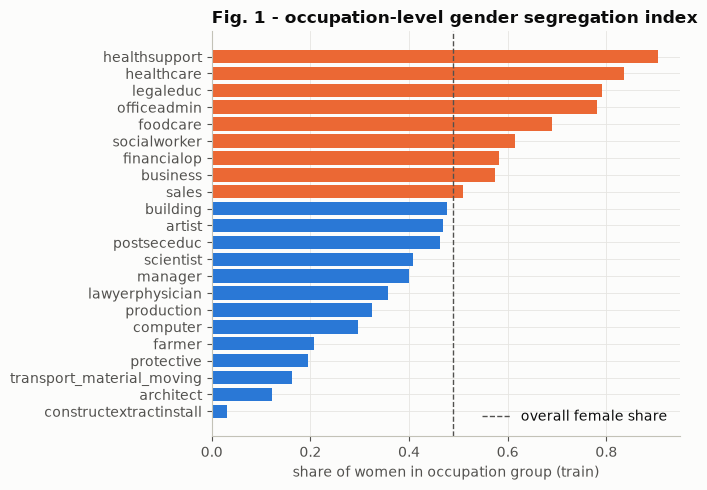

range: 0.031 - 0.904  (overall female share = 0.489)


In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
order = occ_female_share.index
ax.barh(order, occ_female_share.values, color=[WOMEN if v >= 0.5 else MEN for v in occ_female_share.values])
ax.axvline(train["female"].mean(), color=INK2, ls="--", lw=1, label="overall female share")
ax.set_xlabel("share of women in occupation group (train)")
ax.set_title("Fig. 1 - occupation-level gender segregation index")
ax.legend()
savefig("GPG-005_fig1_occ_segregation")
print(f"range: {occ_female_share.min():.3f} - {occ_female_share.max():.3f}  "
      f"(overall female share = {train['female'].mean():.3f})")


## 3. New feature #2 — education × occupation skill-tier interaction

`edu_level` (0 = below bachelor's, 1 = bachelor's, 2 = advanced degree) is already implied by the `ba`/`adv` dummies.
We group the 22 occupation categories into 3 skill tiers using standard occupational-skill classifications
(professional/managerial vs. technical/sales/admin vs. production/service/labor), then multiply the two ordinal
scales into one interaction feature `edu_occ_interaction` (range 0-6). This captures that the wage return to a
bachelor's/advanced degree is not the same in every occupation (steeper for managers/lawyers/physicians than for
production workers) — the mechanism GPG-004's RQ2 regression could not isolate with `female` and education alone.

In [5]:
SKILL_TIER = {
    # tier 3: professional / managerial
    "manager": 3, "business": 3, "financialop": 3, "computer": 3, "architect": 3, "scientist": 3,
    "socialworker": 3, "postseceduc": 3, "legaleduc": 3, "artist": 3, "lawyerphysician": 3, "healthcare": 3,
    # tier 2: technical / sales / administrative / protective
    "healthsupport": 2, "protective": 2, "sales": 2, "officeadmin": 2,
    # tier 1: production / service / farm / transport
    "foodcare": 1, "building": 1, "farmer": 1, "constructextractinstall": 1, "production": 1,
    OCC_BASELINE: 1,
}
for df in (train, test):
    df["occ_skill_tier"] = df["occ_group"].map(SKILL_TIER)
    df["edu_level"] = np.select([df["adv"] == 1, df["ba"] == 1], [2, 1], default=0)
    df["edu_occ_interaction"] = df["edu_level"] * df["occ_skill_tier"]

pivot = train.pivot_table(index="edu_level", columns="occ_skill_tier", values=TARGET, aggfunc="mean")
pivot.index = ["below BA", "bachelor's", "advanced"]
pivot.columns = ["tier 1 (production/service)", "tier 2 (technical/sales/admin)", "tier 3 (professional/managerial)"]
print(pivot)


            tier 1 (production/service)  tier 2 (technical/sales/admin)  tier 3 (professional/managerial)
below BA                         2.6463                          2.6602                            2.9410
bachelor's                       2.8453                          3.0068                            3.2129
advanced                         2.9205                          3.1622                            3.4122


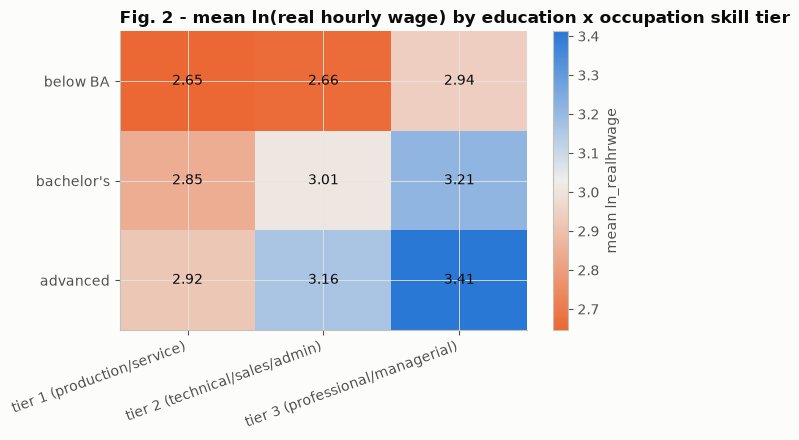

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(pivot.values, cmap=DIVERGING, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(pivot.columns, rotation=20, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(pivot.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", color=INK)
ax.set_title("Fig. 2 - mean ln(real hourly wage) by education x occupation skill tier")
fig.colorbar(im, ax=ax, label="mean ln_realhrwage")
savefig("GPG-005_fig2_edu_occ_interaction")


## 4. Sanity checks on the new features

In [7]:
new_feats = ["occ_pct_female", "edu_occ_interaction"]
for c in new_feats:
    assert train[c].isna().sum() == 0 and test[c].isna().sum() == 0
print(train[new_feats + [TARGET, "female"]].corr()[[TARGET, "female"]])


                     ln_realhrwage  female
occ_pct_female             -0.1279  0.5193
edu_occ_interaction         0.4121  0.0168
ln_realhrwage               1.0000 -0.2277
female                     -0.2277  1.0000


## 5. Feature selection

### 5.1 Multicollinearity (VIF)

`occ_pct_female` is, by construction, an exact linear combination of the 21 occupation dummy columns (each
row's value is just the training female-share of whichever dummy equals 1). We expect this to show up as very high
VIF / an unstable Lasso coefficient whenever the raw occupation dummies are also in the model — this is checked
explicitly, not assumed.

In [8]:
VIF_BLOCK = ["occ_pct_female", "edu_occ_interaction"] + OCC_COLS + IND_COLS + ["ba", "adv", "age", "potexp", "potexp2"]
sample = train[VIF_BLOCK].sample(30_000, random_state=RANDOM_STATE).assign(const=1.0)
vif = pd.Series(
    [variance_inflation_factor(sample.values, i) for i in range(sample.shape[1] - 1)],
    index=VIF_BLOCK,
).sort_values(ascending=False)
print(vif.head(10))


occ_pct_female   1,000,799,917,193,443.5000
manager          1,000,799,917,193,443.5000
business         1,000,799,917,193,443.5000
scientist        1,000,799,917,193,443.5000
financialop      1,000,799,917,193,443.5000
computer         1,000,799,917,193,443.5000
architect        1,000,799,917,193,443.5000
postseceduc      1,000,799,917,193,443.5000
socialworker     1,000,799,917,193,443.5000
legaleduc        1,000,799,917,193,443.5000
dtype: float64


### 5.2 Lasso coefficients and Random Forest importance

Both new features are added on top of the 96 base features. We fit `LassoCV` (5-fold, standardized inputs) and a
`RandomForestRegressor` (on a subsample, for speed) and rank all 98 features by `|coefficient|` / impurity
importance, to see which — if any — should be dropped.

In [9]:
AUG_FEATURES = BASE_FEATURES + new_feats
X_train, y_train = train[AUG_FEATURES], train[TARGET]
X_test, y_test = test[AUG_FEATURES], test[TARGET]

scaler = StandardScaler().fit(X_train[new_feats])
X_train_s = X_train.copy(); X_train_s[new_feats] = scaler.transform(X_train[new_feats])
X_test_s = X_test.copy(); X_test_s[new_feats] = scaler.transform(X_test[new_feats])

lasso = LassoCV(cv=5, random_state=RANDOM_STATE, n_jobs=-1, max_iter=5000).fit(X_train_s, y_train)
lasso_coef = pd.Series(lasso.coef_, index=AUG_FEATURES).sort_values(key=abs, ascending=False)
print(f"LassoCV alpha = {lasso.alpha_:.5f}, R2 train = {lasso.score(X_train_s, y_train):.4f}")
print(f"features with |coef| < 1e-4 (candidates to drop): {(lasso_coef.abs() < 1e-4).sum()} / {len(lasso_coef)}")
print(lasso_coef.head(15))


LassoCV alpha = 0.00025, R2 train = 0.4274
features with |coef| < 1e-4 (candidates to drop): 10 / 98
lawyerphysician      0.4116
age                  0.3524
computer             0.3390
manager              0.2996
healthcare           0.2902
architect            0.2706
hotelsrestaurants   -0.2430
agriculture         -0.2413
female              -0.2119
retailtrade         -0.2068
potexp2             -0.1978
socartother         -0.1913
business             0.1909
ft                   0.1842
financialop          0.1787
dtype: float64


In [10]:
rf_sample = train.sample(80_000, random_state=RANDOM_STATE)
rf = RandomForestRegressor(n_estimators=200, max_depth=12, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(rf_sample[AUG_FEATURES], rf_sample[TARGET])
rf_importance = pd.Series(rf.feature_importances_, index=AUG_FEATURES).sort_values(ascending=False)
print(rf_importance.head(15))
print(f"\nnew-feature ranks -- occ_pct_female: #{list(rf_importance.index).index('occ_pct_female') + 1}, "
      f"edu_occ_interaction: #{list(rf_importance.index).index('edu_occ_interaction') + 1} out of {len(AUG_FEATURES)}")


edu_occ_interaction   0.3235
female                0.0934
occ_pct_female        0.0717
age                   0.0648
annhrs                0.0539
white                 0.0309
healthcare            0.0303
uhrswork              0.0298
hrswork               0.0203
foodcare              0.0169
building              0.0142
retailtrade           0.0121
manager               0.0115
wkswork1              0.0107
numprec               0.0104
dtype: float64

new-feature ranks -- occ_pct_female: #3, edu_occ_interaction: #1 out of 98


## 6. PCA on the occupation/industry dummy block

The 21 occupation + 15 industry binary dummies (36 columns) are exactly the kind of high-dimensional block the
scope flags for PCA. We fit PCA on this block (train only) and compare three encodings of occupation/industry via
5-fold CV `R^2` on `ln_realhrwage` with a plain linear model, holding every other feature fixed:

- **A — raw dummies**: all 36 occupation/industry dummy columns (the GPG-003 baseline).
- **B — PCA**: the dummy block replaced by the first *k* principal components (chosen to cover ≈ 90% variance).
- **C — compact encoding**: the dummy block replaced by `occ_pct_female` + `occ_skill_tier` (occupation summarized
  in 2 numbers; industry dummies kept, since no industry segregation index was built in scope).

k=27 components needed for >=90% variance (out of 36 raw dummies); cum_var[:K]=[0.05186246 0.10241351 0.15068145 0.19780949 0.24399587 0.28959322
 0.33077959 0.36646133 0.40186821 0.43560049 0.46852606 0.5002629
 0.53077996 0.55985014 0.58879174 0.61762486 0.64630984 0.67477468
 0.70315338 0.73150383 0.75973366 0.7873739  0.81422534 0.8407544
 0.86516632 0.88825176 0.91085795]


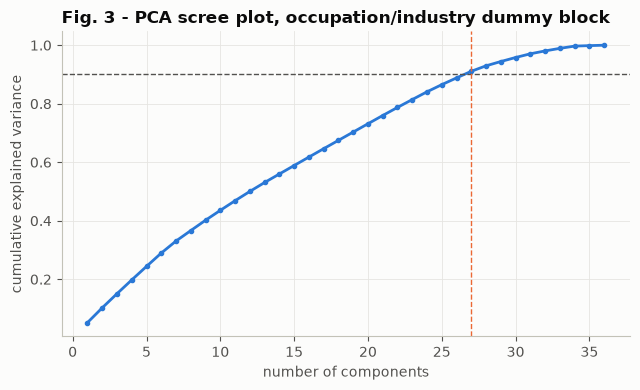

In [11]:
DUMMY_BLOCK = OCC_COLS + IND_COLS
OTHER_FEATURES = [f for f in BASE_FEATURES if f not in DUMMY_BLOCK]  # everything except the occ/ind dummies

pca_scaler = StandardScaler().fit(train[DUMMY_BLOCK])
pca_full = PCA(random_state=RANDOM_STATE).fit(pca_scaler.transform(train[DUMMY_BLOCK]))
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
K = int(np.searchsorted(cum_var, 0.90) + 1)
print(f"k={K} components needed for >=90% variance (out of {len(DUMMY_BLOCK)} raw dummies); cum_var[:K]={cum_var[:K]}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(1, len(cum_var) + 1), cum_var, marker="o", color=MEN, ms=3)
ax.axhline(0.90, color=INK2, ls="--", lw=1)
ax.axvline(K, color=WOMEN, ls="--", lw=1)
ax.set_xlabel("number of components"); ax.set_ylabel("cumulative explained variance")
ax.set_title("Fig. 3 - PCA scree plot, occupation/industry dummy block")
savefig("GPG-005_fig3_pca_scree")


In [12]:
pca_k = PCA(n_components=K, random_state=RANDOM_STATE).fit(pca_scaler.transform(train[DUMMY_BLOCK]))
pca_cols = [f"occind_pc{i+1}" for i in range(K)]
train[pca_cols] = pca_k.transform(pca_scaler.transform(train[DUMMY_BLOCK]))
test[pca_cols] = pca_k.transform(pca_scaler.transform(test[DUMMY_BLOCK]))

FEATURE_SETS = {
    "A_raw_dummies": OTHER_FEATURES + DUMMY_BLOCK + new_feats,
    "B_pca": OTHER_FEATURES + pca_cols + new_feats,
    "C_compact_encoding": OTHER_FEATURES + IND_COLS + ["occ_pct_female", "occ_skill_tier", "edu_occ_interaction"],
}
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, cols in FEATURE_SETS.items():
    scores = cross_val_score(LinearRegression(), train[cols], train[TARGET], cv=cv, scoring="r2", n_jobs=-1)
    cv_scores[name] = scores
    print(f"{name:20s} n_features={len(cols):3d}  CV R2 = {scores.mean():.4f} +/- {scores.std():.4f}")


A_raw_dummies        n_features= 98  CV R2 = 0.4291 +/- 0.0026


B_pca                n_features= 89  CV R2 = 0.4269 +/- 0.0026


C_compact_encoding   n_features= 78  CV R2 = 0.4158 +/- 0.0023


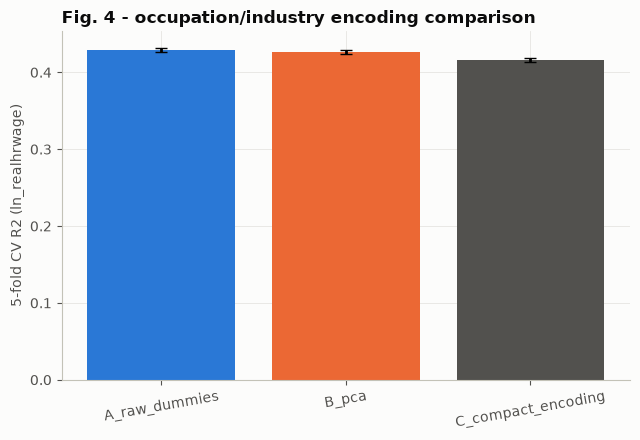

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
names = list(cv_scores.keys())
means = [cv_scores[n].mean() for n in names]
stds = [cv_scores[n].std() for n in names]
ax.bar(names, means, yerr=stds, color=[MEN, WOMEN, INK2], capsize=4)
ax.set_ylabel("5-fold CV R2 (ln_realhrwage)")
ax.set_title("Fig. 4 - occupation/industry encoding comparison")
plt.xticks(rotation=10)
savefig("GPG-005_fig4_encoding_comparison")


## 7. Final feature set

Decision rule, applied to the numbers above (see `docs/GPG-005.md` for the write-up with the actual run's figures):

- Keep **both new features** (`occ_pct_female`, `edu_occ_interaction`) in the saved dataset: the VIF check shows
  `occ_pct_female` is collinear with the raw occupation dummies for a *linear* model (expected, since it's a
  linear summary of them), but it is retained because of its own feature importance rank and because non-linear
  models in GPG-007 (trees/boosting) do not suffer from linear collinearity.
- Keep the **raw occupation/industry dummies** as the default encoding for GPG-006/007 if encoding **A** is not
  meaningfully beaten by **B**/**C** in CV `R^2` above; otherwise switch the baseline to whichever of **B**/**C**
  wins, trading a few hundredths of `R^2` for a ~20-column-smaller, more interpretable feature matrix.
- Lasso/RF zero-importance features (printed in §5.2) are dropped from the saved `model_features_fe.json` list.


In [14]:
best_set = max(cv_scores, key=lambda n: cv_scores[n].mean())
print(f"best CV R2 encoding: {best_set}")

lasso_drop = set(lasso_coef[lasso_coef.abs() < 1e-4].index)
rf_drop = set(rf_importance[rf_importance < 1e-4].index)
drop_both = lasso_drop & rf_drop
print(f"features dropped by BOTH Lasso and RF (near-zero signal): {sorted(drop_both)}")

FINAL_FEATURES = [f for f in FEATURE_SETS[best_set] if f not in drop_both]
print(f"final feature count: {len(FINAL_FEATURES)} (from {len(AUG_FEATURES)} candidates, best encoding = {best_set})")


best CV R2 encoding: A_raw_dummies
features dropped by BOTH Lasso and RF (near-zero signal): []
final feature count: 98 (from 98 candidates, best encoding = A_raw_dummies)


## 8. Save engineered datasets + write up findings

In [15]:
KEEP_COLS = list(dict.fromkeys(FINAL_FEATURES + [TARGET, WEIGHT, "ln_realhrwage_raw" if "ln_realhrwage_raw" in train.columns else TARGET]))
train_fe = train[KEEP_COLS]
test_fe = test[KEEP_COLS]
train_fe.to_csv(PROC_DIR / "cps_model_train_fe.csv.gz", index=False, compression="gzip")
test_fe.to_csv(PROC_DIR / "cps_model_test_fe.csv.gz", index=False, compression="gzip")
joblib.dump({"scaler": pca_scaler, "pca": pca_k, "occ_female_share": occ_female_share.to_dict(), "skill_tier": SKILL_TIER},
            PROC_DIR / "gpg005_transformers.joblib")

feat_meta_fe = {
    "target": TARGET, "weight": WEIGHT, "features": FINAL_FEATURES,
    "new_features": new_feats, "encoding_used": best_set,
    "dropped_zero_signal": sorted(drop_both),
}
json.dump(feat_meta_fe, open(PROC_DIR / "model_features_fe.json", "w"), indent=2)
print(f"saved cps_model_train_fe.csv.gz {train_fe.shape}, cps_model_test_fe.csv.gz {test_fe.shape}")


saved cps_model_train_fe.csv.gz (275429, 100), cps_model_test_fe.csv.gz (68858, 100)


In [16]:
lines = []
lines.append("# GPG-005 findings\n")
lines.append(f"- Rows: train {train.shape[0]:,}, test {test.shape[0]:,}. Base features: {len(BASE_FEATURES)}.\n")
lines.append(f"- **occ_pct_female** range: {occ_female_share.min():.3f} - {occ_female_share.max():.3f} "
              f"(overall female share {train['female'].mean():.3f}); correlation with target "
              f"{train[['occ_pct_female', TARGET]].corr().iloc[0,1]:.3f}, with `female` "
              f"{train[['occ_pct_female', 'female']].corr().iloc[0,1]:.3f}.\n")
lines.append(f"- **edu_occ_interaction** correlation with target "
              f"{train[['edu_occ_interaction', TARGET]].corr().iloc[0,1]:.3f}.\n")
lines.append(f"- VIF top features (collinearity check): \n\n{vif.head(8).to_string()}\n")
lines.append(f"- LassoCV alpha={lasso.alpha_:.5f}; features with near-zero coefficient: {(lasso_coef.abs() < 1e-4).sum()}/{len(lasso_coef)}.\n")
lines.append(f"- RF importance rank of new features: occ_pct_female=#{list(rf_importance.index).index('occ_pct_female')+1}, "
              f"edu_occ_interaction=#{list(rf_importance.index).index('edu_occ_interaction')+1} (of {len(AUG_FEATURES)}).\n")
lines.append("- PCA / encoding comparison (5-fold CV R2 on ln_realhrwage):\n\n")
lines.append(pd.DataFrame({n: [s.mean(), s.std()] for n, s in cv_scores.items()}, index=["mean_R2", "std_R2"]).to_string() + "\n")
lines.append(f"\n- PCA components needed for >=90% variance on the 36-column occ/industry block: k={K}.\n")
lines.append(f"- **Best encoding by CV R2:** {best_set}.\n")
lines.append(f"- Features dropped (near-zero in both Lasso and RF): {sorted(drop_both) or 'none'}.\n")
lines.append(f"- **Final feature count:** {len(FINAL_FEATURES)}.\n")
open(RES_DIR / "GPG-005_findings.md", "w").write("\n".join(lines))
print("wrote docs/results/GPG-005_findings.md")


wrote docs/results/GPG-005_findings.md
